# GNN Project


Dans quelle mesure la structure topologique du réseau aérien améliore-t-elle la prédiction du pays d’un aéroport par rapport à ses seules caractéristiques individuelles ?

In [51]:
import html as html_lib
import re

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns
import torch as th
import torch.nn.functional as F
from matplotlib.cm import ScalarMappable
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from torch import nn
from torch_geometric.nn import GATConv, GCNConv, SGConv, VGAE
from torch_geometric.transforms import RandomLinkSplit
from torch_geometric.utils import from_networkx, to_networkx


In [20]:
# Load graph

G = nx.read_graphml("airportsAndCoordAndPop.graphml")
G.nodes(data=True)

NodeDataView({'0': {'lon': -145.50972222222222, 'lat': -17.35388888888889, 'population': 10000, 'country': 'FRENCH_POLYNESIA', 'city_name': 'Anaa'}, '1': {'lon': -140.95, 'lat': -18.066666666666666, 'population': 10000, 'country': 'FRENCH_POLYNESIA', 'city_name': 'Hao Island'}, '2': {'lon': -149.6, 'lat': -17.55, 'population': 26357, 'country': 'FRENCH_POLYNESIA', 'city_name': 'Papeete'}, '3': {'lon': -135.0, 'lat': -23.033333333333335, 'population': 10000, 'country': 'FRENCH_POLYNESIA', 'city_name': 'Gambier Island'}, '4': {'lon': -143.65725, 'lat': -16.584888888888887, 'population': 10000, 'country': 'FRENCH_POLYNESIA', 'city_name': 'Makemo'}, '5': {'lon': 174.79166666666666, 'lat': -37.00805555555556, 'population': 417910, 'country': 'NEW_ZEALAND', 'city_name': 'Auckland'}, '6': {'lon': -139.03333333333333, 'lat': -9.8, 'population': 10000, 'country': 'FRENCH_POLYNESIA', 'city_name': 'Atuona'}, '7': {'lon': -151.75, 'lat': -16.45, 'population': 10000, 'country': 'FRENCH_POLYNESIA', 

In [21]:
print("Number of nodes : ",len(G.nodes))

Number of nodes :  3363


In [22]:
print("Number of edges : ",len(G.edges))

Number of edges :  13547


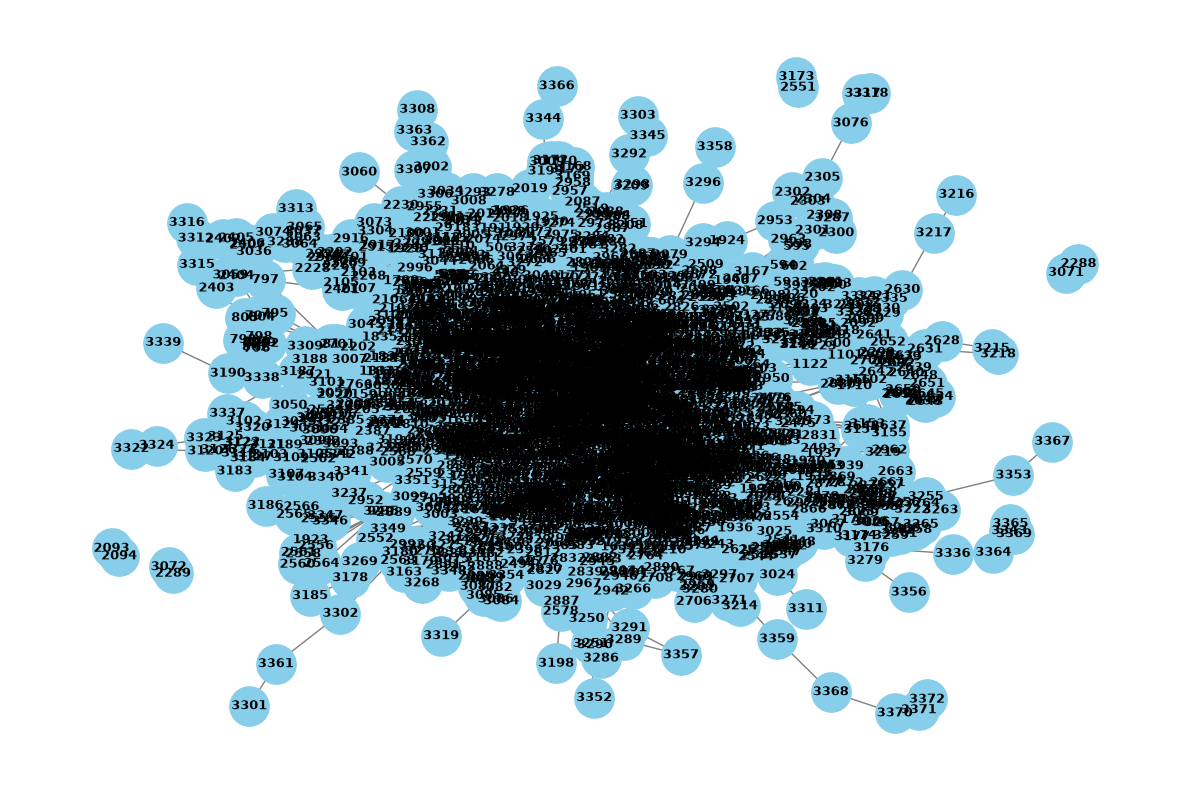

In [23]:
# First visualization

plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G,
    pos=pos,
    node_size=800,
    node_color="skyblue",
    edge_color="gray",
    font_size=9,
    font_weight="bold",
    arrows=True
)

plt.axis("off")
plt.tight_layout()
plt.show()

### Better visualization for a large graph

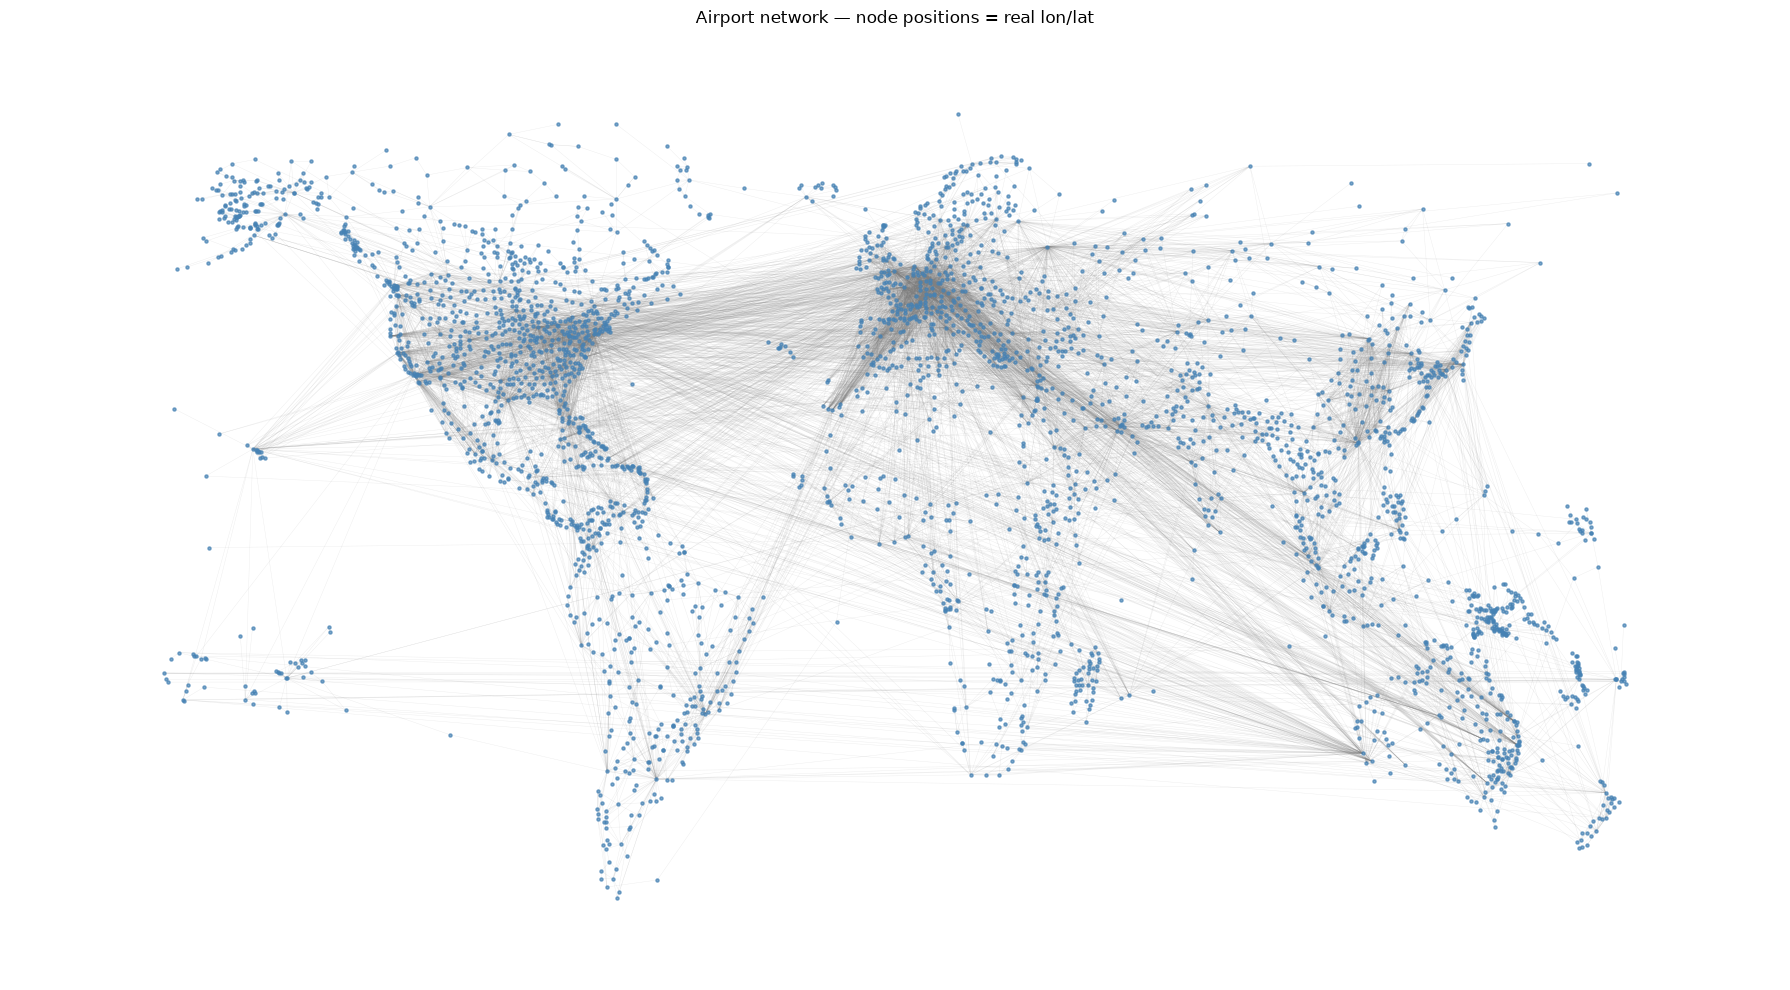

In [24]:
# Static visualization using real geographic coordinates as node positions

geo_pos = {n: (d["lon"], d["lat"]) for n, d in G.nodes(data=True)}

plt.figure(figsize=(18, 10))
nx.draw_networkx_edges(G, pos=geo_pos, width=0.3, alpha=0.15, edge_color="gray")
nx.draw_networkx_nodes(G, pos=geo_pos, node_size=5, node_color="steelblue", alpha=0.7)

plt.axis("off")
plt.title("Airport network — node positions = real lon/lat")
plt.tight_layout()
plt.show()

In [25]:
# Interactive visualization (zoom / pan / hover) with Plotly

# Edges as a single trace, segments separated by None to avoid one trace per edge
edge_lon, edge_lat = [], []
for u, v in G.edges():
    edge_lon += [G.nodes[u]["lon"], G.nodes[v]["lon"], None]
    edge_lat += [G.nodes[u]["lat"], G.nodes[v]["lat"], None]

edge_trace = go.Scattergeo(
    lon=edge_lon,
    lat=edge_lat,
    mode="lines",
    line=dict(width=0.5, color="rgba(100,100,100,0.3)"),
    hoverinfo="none",
    showlegend=False,
)

node_lon = [d["lon"] for _, d in G.nodes(data=True)]
node_lat = [d["lat"] for _, d in G.nodes(data=True)]
node_pop = np.array([d["population"] for _, d in G.nodes(data=True)], dtype=float)
node_text = [
    f"{d['city_name']} ({d['country']})<br>Population: {d['population']:,}"
    for _, d in G.nodes(data=True)
]
# Scale marker size with log(population) so both small and huge cities stay visible
node_size = 3 + 8 * (np.log1p(node_pop) / np.log1p(node_pop).max())

node_trace = go.Scattergeo(
    lon=node_lon,
    lat=node_lat,
    mode="markers",
    marker=dict(
        size=node_size,
        color=node_pop,
        colorscale="Viridis",
        cmin=0,
        colorbar=dict(title="Population"),
        line=dict(width=0),
    ),
    text=node_text,
    hoverinfo="text",
    showlegend=False,
)

fig = go.Figure(data=[edge_trace, node_trace])
fig.update_layout(
    title="Airport network — interactive map (zoom / pan / hover)",
    geo=dict(
        projection_type="natural earth",
        showland=True,
        landcolor="rgb(243, 243, 243)",
        countrycolor="rgb(204, 204, 204)",
    ),
    height=700,
    margin=dict(l=0, r=0, t=40, b=0),
)
fig.show()


We have noticed disparity. There are aiports that represent hub with high degrees. In other hand some of the aerport have very low degree. It exists countries with only one airport or in any case a very little number of airport, this introduce unbalanced class

## Classification task: predicting an airport's country

The target class is the `country` node attribute. Before building a classifier, let's look at how many classes (countries) there are and how balanced they are.

In [26]:
# Number of classes (countries) and number of airports per class

country_counts = pd.Series([d["country"] for _, d in G.nodes(data=True)]).value_counts()

print(f"Number of nodes: {G.number_of_nodes()}")
print(f"Number of classes (countries): {len(country_counts)}")
print(f"Airports per class -> min: {country_counts.min()}, median: {country_counts.median():.0f}, "
      f"mean: {country_counts.mean():.1f}, max: {country_counts.max()}")
print(f"Classes with a single airport: {(country_counts == 1).sum()}")
print(f"Classes with fewer than 3 airports: {(country_counts < 3).sum()}")

country_counts.head(15)

Number of nodes: 3363
Number of classes (countries): 212
Airports per class -> min: 1, median: 4, mean: 15.9, max: 650
Classes with a single airport: 62
Classes with fewer than 3 airports: 86


USA                     650
CANADA                  243
AUSTRALIA               207
BRAZIL                  105
CHINA                    93
PAPUA_NEW_GUINEA         92
RUSSIA                   70
JAPAN                    69
M&Eacute;XICO#MEXICO     59
ARGENTINA                57
INDIA                    57
FRANCE                   56
INDONESIA                47
NORWAY                   46
COLOMBIA                 42
Name: count, dtype: int64

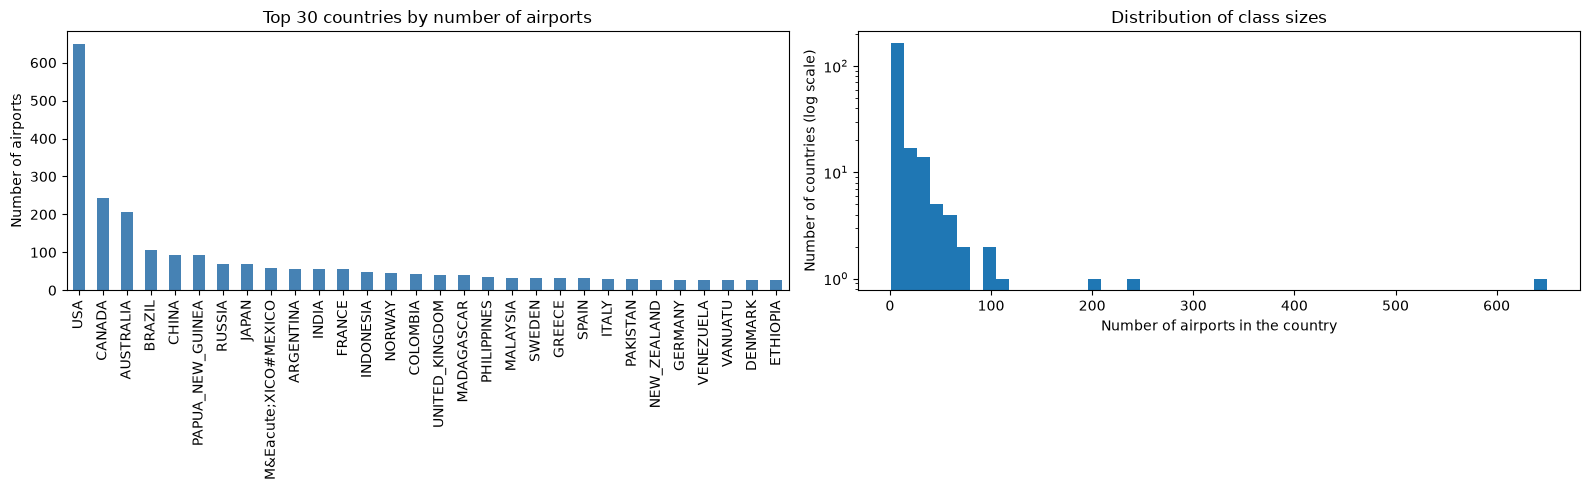

In [27]:
# Visualize the class imbalance: top 30 countries by airport count,
# plus the distribution of class sizes (log scale, since it's very skewed)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

country_counts.head(30).plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Top 30 countries by number of airports")
axes[0].set_ylabel("Number of airports")

axes[1].hist(country_counts, bins=50)
axes[1].set_yscale("log")
axes[1].set_xlabel("Number of airports in the country")
axes[1].set_ylabel("Number of countries (log scale)")
axes[1].set_title("Distribution of class sizes")

plt.tight_layout()
plt.show()

**Observation:** 212 classes for 3363 nodes, heavily imbalanced (USA alone has 650 airports, median is only 4 per country, and 62 countries have a single airport). This matters for the rest :
- A single-sample class can't appear in both train and test, so a classifier can never be correct on it - worth deciding whether to keep, merge, or drop very small classes.
- Accuracy will be dominated by big classes (USA, Canada, Australia...); a per-class metric (e.g. macro F1 or a confusion matrix) will give a fairer picture than raw accuracy.

## Data quality

Before training anything, let's check the raw attributes (`lon`, `lat`, `population`, `country`, `city_name`) for missing values and inconsistencies.

In [28]:
# Missing values and obviously invalid values

attrs_df = pd.DataFrame([d for _, d in G.nodes(data=True)])

print("Shape:", attrs_df.shape)
print("\nMissing values per column:")
print(attrs_df.isna().sum())

print("\nEmpty-string values per text column:")
for col in ["country", "city_name"]:
    print(f"  {col}: {(attrs_df[col].str.strip() == '').sum()}")

print("\npopulation <= 0:", (attrs_df["population"] <= 0).sum())
print("lon out of [-180, 180]:", ((attrs_df['lon'] < -180) | (attrs_df['lon'] > 180)).sum())
print("lat out of [-90, 90]:", ((attrs_df['lat'] < -90) | (attrs_df['lat'] > 90)).sum())
print("duplicated rows (exact):", attrs_df.duplicated().sum())

Shape: (3363, 5)

Missing values per column:
lon           0
lat           0
population    0
country       0
city_name     0
dtype: int64

Empty-string values per text column:
  country: 0
  city_name: 0

population <= 0: 0
lon out of [-180, 180]: 0
lat out of [-90, 90]: 0
duplicated rows (exact): 0


No missing/empty/out-of-range values and no exact duplicate rows. But that doesn't mean the data is clean, let's dig into the `country` labels, since `M&Eacute;XICO#MEXICO` already looked suspicious.

In [29]:
# Malformed country labels: HTML entities (e.g. "&Eacute;") and "#"-concatenated alias variants

all_countries = sorted(attrs_df["country"].unique())
print("Unique country labels:", len(all_countries))

html_entity_labels = [c for c in all_countries if re.search(r"&\w+;", c)]
hash_labels = [c for c in all_countries if "#" in c]

print(f"\nLabels containing an HTML entity: {len(html_entity_labels)}")
for c in html_entity_labels:
    print(" ", c)

print(f"\nLabels containing '#' (alias concatenation): {len(hash_labels)}")
for c in hash_labels:
    print(" ", c)

Unique country labels: 212

Labels containing an HTML entity: 4
  HA&Iuml;TI#HAITI
  M&Eacute;XICO#MEXICO
  PER&Uacute;#PERU
  VI&Ecirc;T_NAM#VIET_NAM,VIETNAM

Labels containing '#' (alias concatenation): 9
  HA&Iuml;TI#HAITI
  M&Eacute;XICO#MEXICO
  PER&Uacute;#PERU
  SAINT-PIERRE_AND_MIQUELON#ST-PIERRE_AND_MIQUELON
  SAINT_HELENA#ST_HELENA
  SAINT_KITTS_AND_NEVIS#ST_KITTS_AND_NEVIS
  SAINT_LUCIA#ST_LUCIA
  SAINT_VINCENT_AND_THE_GRENADINES#ST_VINCENT_AND_THE_GRENADINES
  VI&Ecirc;T_NAM#VIET_NAM,VIETNAM


In [30]:
# Does cleaning these labels actually merge any classes together?
# (i.e. is there, e.g., a clean "MEXICO" label elsewhere that "M&Eacute;XICO#MEXICO" is a duplicate of?)

cleaned = attrs_df["country"].apply(lambda c: html_lib.unescape(c).split("#")[0])
print("Unique classes before cleaning:", attrs_df["country"].nunique())
print("Unique classes after cleaning:", cleaned.nunique())

Unique classes before cleaning: 212
Unique classes after cleaning: 212


Still 212 classes after cleaning: none of the 9 malformed labels has a "clean" twin elsewhere in the dataset, so this isn't label fragmentation splitting one country into several classes, it's just unreadable strings (worth cleaning for display/readability, e.g. in plot legends, but it doesn't change the classification problem itself).

## filter out classes that are too small

In [31]:
MIN_CLASS_SIZE = 3

country_counts_full = pd.Series([d["country"] for _, d in G.nodes(data=True)]).value_counts()
kept_countries = set(country_counts_full[country_counts_full >= MIN_CLASS_SIZE].index)

nodes_to_keep = [n for n, d in G.nodes(data=True) if d["country"] in kept_countries]
G_filtered = G.subgraph(nodes_to_keep).copy()

print(f"Classes: {country_counts_full.shape[0]} -> {len(kept_countries)} "
      f"(removed {country_counts_full.shape[0] - len(kept_countries)} classes with < {MIN_CLASS_SIZE} airports)")
print(f"Nodes: {G.number_of_nodes()} -> {G_filtered.number_of_nodes()} "
      f"(removed {G.number_of_nodes() - G_filtered.number_of_nodes()} nodes)")
print(f"Edges: {G.number_of_edges()} -> {G_filtered.number_of_edges()}")

Classes: 212 -> 126 (removed 86 classes with < 3 airports)
Nodes: 3363 -> 3253 (removed 110 nodes)
Edges: 13547 -> 12272


##  train/val/test split

In [32]:
def class_balanced_split(labels, val_frac=0.15, test_frac=0.15, seed=0):
    """Per-class split that guarantees >=1 sample per class in val and test."""
    rng = np.random.RandomState(seed)
    labels = np.asarray(labels)
    train_idx, val_idx, test_idx = [], [], []
    for c in np.unique(labels):
        idx_c = np.where(labels == c)[0].copy()
        rng.shuffle(idx_c)
        n = len(idx_c)
        n_val = max(1, round(n * val_frac))
        n_test = max(1, round(n * test_frac))
        if n_val + n_test >= n:  # very small class: 1/1/rest
            n_val, n_test = 1, 1
        n_train = n - n_val - n_test
        train_idx.extend(idx_c[:n_train])
        val_idx.extend(idx_c[n_train:n_train + n_val])
        test_idx.extend(idx_c[n_train + n_val:])
    return np.array(train_idx), np.array(val_idx), np.array(test_idx)

In [33]:
node_ids = np.array(list(G_filtered.nodes()))
labels = np.array([G_filtered.nodes[n]["country"] for n in node_ids])

train_idx, val_idx, test_idx = class_balanced_split(labels, seed=0)

n = len(labels)
print(f"train: {len(train_idx)} ({len(train_idx)/n:.1%})")
print(f"val:   {len(val_idx)} ({len(val_idx)/n:.1%})")
print(f"test:  {len(test_idx)} ({len(test_idx)/n:.1%})")
print(f"classes missing from train/val/test: "
      f"{len(set(labels) - set(labels[train_idx]))}/"
      f"{len(set(labels) - set(labels[val_idx]))}/"
      f"{len(set(labels) - set(labels[test_idx]))}")

train: 2243 (69.0%)
val:   505 (15.5%)
test:  505 (15.5%)
classes missing from train/val/test: 0/0/0


In [34]:
# Features (lon, lat, log1p(population)) + label encoding.
# Scaler is fit on the train split only to avoid leakage.

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(labels)

X_raw = np.array([
    [G_filtered.nodes[n]["lon"], G_filtered.nodes[n]["lat"], np.log1p(G_filtered.nodes[n]["population"])]
    for n in node_ids
])

scaler = StandardScaler().fit(X_raw[train_idx])
X = scaler.transform(X_raw)

print("X:", X.shape, " y:", y.shape, " classes:", len(label_encoder.classes_))
print("feature means (train):", X[train_idx].mean(axis=0).round(2))
print("feature stds (train):", X[train_idx].std(axis=0).round(2))

X: (3253, 3)  y: (3253,)  classes: 126
feature means (train): [-0.  0.  0.]
feature stds (train): [1. 1. 1.]


# Part 1 : Machine Learning / Deep Learning (no graph model)

Condition : predict the country of the airport without using the information provided by the graph structure

In [47]:
# features only (lon, lat, population), no graph, first result preview on seed 0

feature_only_models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0),
}

feature_only_results = {}
for name, clf in feature_only_models.items():
    clf.fit(X[train_idx], y[train_idx])
    pred_test = clf.predict(X[test_idx])
    macro_f1 = f1_score(y[test_idx], pred_test, average="macro")
    bal_acc = balanced_accuracy_score(y[test_idx], pred_test)
    raw_acc = (pred_test == y[test_idx]).mean()
    feature_only_results[name] = {"macro_f1": macro_f1, "balanced_acc": bal_acc, "raw_acc": raw_acc}
    print(f"{name:20s} macro-F1={macro_f1:.3f}  balanced_acc={bal_acc:.3f}  raw_acc={raw_acc:.3f}")

LogisticRegression   macro-F1=0.133  balanced_acc=0.195  raw_acc=0.329
RandomForest         macro-F1=0.578  balanced_acc=0.626  raw_acc=0.782


In [48]:
# Features-only models: compare lon/lat with 3D unit-sphere coordinates (x, y, z).

n_classes = len(label_encoder.classes_)

lon_rad, lat_rad = np.radians(X_raw[:, 0]), np.radians(X_raw[:, 1])
X_xyz_raw = np.column_stack([
    np.cos(lat_rad) * np.cos(lon_rad),
    np.cos(lat_rad) * np.sin(lon_rad),
    np.sin(lat_rad),
    X_raw[:, 2],
])

feature_sets = {"lon/lat": X_raw, "xyz": X_xyz_raw}

In [49]:
# Small hyperparameter search for the MLP architecture (hidden size, number of layers,
# learning rate, dropout), on the validation set of seed 0 only (xyz features)

mlp_search_configs = [
    (64, 1, 0.005, 0.2), (128, 1, 0.005, 0.2), (256, 1, 0.005, 0.2),
    (64, 2, 0.005, 0.2), (128, 2, 0.005, 0.2), (256, 2, 0.005, 0.2),
    (128, 2, 0.001, 0.3), (128, 2, 0.01, 0.1), (128, 3, 0.005, 0.3),
    (256, 2, 0.005, 0.1), (256, 3, 0.005, 0.2),
    (256, 2, 0.005, 0.0), (256, 2, 0.005, 0.05), (256, 2, 0.01, 0.1),
    (384, 2, 0.005, 0.1), (256, 2, 0.003, 0.1), (256, 1, 0.005, 0.1),
]


def make_mlp(in_dim, out_dim, hidden, n_layers, dropout):
    layers, dim = [], in_dim
    for _ in range(n_layers):
        layers += [nn.Linear(dim, hidden), nn.ReLU(), nn.Dropout(dropout)]
        dim = hidden
    layers += [nn.Linear(dim, out_dim)]
    return nn.Sequential(*layers)

In [52]:
tr0, va0, _ = class_balanced_split(labels, seed=0)
X_xyz_s0 = StandardScaler().fit(X_xyz_raw[tr0]).transform(X_xyz_raw)
Xt0, yt0 = th.tensor(X_xyz_s0, dtype=th.float), th.tensor(y, dtype=th.long)
tr0_t, va0_t = th.tensor(tr0), th.tensor(va0)
cw0 = th.tensor(compute_class_weight("balanced", classes=np.arange(n_classes), y=y[tr0]), dtype=th.float)

mlp_search_results = []
for hidden, n_layers, lr, dropout in mlp_search_configs:
    th.manual_seed(0)
    model = make_mlp(Xt0.shape[1], n_classes, hidden, n_layers, dropout)
    optimizer = th.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss(weight=cw0)
    best_val_f1, patience_ctr = -1, 0
    for epoch in range(500):
        model.train()
        optimizer.zero_grad()
        loss = criterion(model(Xt0[tr0_t]), yt0[tr0_t])
        loss.backward()
        optimizer.step()

        model.eval()
        with th.no_grad():
            val_pred = model(Xt0[va0_t]).argmax(dim=1).numpy()
        val_f1 = f1_score(y[va0], val_pred, average="macro")
        if val_f1 > best_val_f1:
            best_val_f1, patience_ctr = val_f1, 0
        else:
            patience_ctr += 1
            if patience_ctr >= 50:
                break
    mlp_search_results.append((hidden, n_layers, lr, dropout, best_val_f1))
    print(f"hidden={hidden:3d} layers={n_layers} lr={lr:<6} dropout={dropout}  val macro-F1={best_val_f1:.3f}")

best_hidden, best_layers, best_lr, best_dropout, best_val_f1 = max(mlp_search_results, key=lambda r: r[-1])
print(f"\nBest: hidden={best_hidden}, layers={best_layers}, lr={best_lr}, dropout={best_dropout}  val macro-F1={best_val_f1:.3f}")

hidden= 64 layers=1 lr=0.005  dropout=0.2  val macro-F1=0.416
hidden=128 layers=1 lr=0.005  dropout=0.2  val macro-F1=0.612
hidden=256 layers=1 lr=0.005  dropout=0.2  val macro-F1=0.629
hidden= 64 layers=2 lr=0.005  dropout=0.2  val macro-F1=0.562
hidden=128 layers=2 lr=0.005  dropout=0.2  val macro-F1=0.593
hidden=256 layers=2 lr=0.005  dropout=0.2  val macro-F1=0.657
hidden=128 layers=2 lr=0.001  dropout=0.3  val macro-F1=0.544
hidden=128 layers=2 lr=0.01   dropout=0.1  val macro-F1=0.656
hidden=128 layers=3 lr=0.005  dropout=0.3  val macro-F1=0.570
hidden=256 layers=2 lr=0.005  dropout=0.1  val macro-F1=0.684
hidden=256 layers=3 lr=0.005  dropout=0.2  val macro-F1=0.598
hidden=256 layers=2 lr=0.005  dropout=0.0  val macro-F1=0.676
hidden=256 layers=2 lr=0.005  dropout=0.05  val macro-F1=0.642
hidden=256 layers=2 lr=0.01   dropout=0.1  val macro-F1=0.673
hidden=384 layers=2 lr=0.005  dropout=0.1  val macro-F1=0.661
hidden=256 layers=2 lr=0.003  dropout=0.1  val macro-F1=0.661
hidden=

In [53]:
# MLP used everywhere below, with the hyperparameters found by the search above.

def train_mlp_features(X, y, tr, va, te, class_weight, seed, hidden=256, lr=0.005, dropout=0.1, patience=50):
    th.manual_seed(seed)
    Xt, yt = th.tensor(X, dtype=th.float), th.tensor(y, dtype=th.long)
    model = nn.Sequential(
        nn.Linear(X.shape[1], hidden), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(hidden, n_classes),
    )
    optimizer = th.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss(weight=class_weight)  # class_weight=None -> unweighted
    tr_t, va_t = th.tensor(tr), th.tensor(va)
    best_val_f1, best_state, patience_ctr = -1, None, 0
    for epoch in range(500):
        model.train()
        optimizer.zero_grad()
        loss = criterion(model(Xt[tr_t]), yt[tr_t])
        loss.backward()
        optimizer.step()

        model.eval()
        with th.no_grad():
            val_pred = model(Xt[va_t]).argmax(dim=1).numpy()
        val_f1 = f1_score(y[va], val_pred, average="macro")
        if val_f1 > best_val_f1:
            best_val_f1, best_state, patience_ctr = val_f1, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    with th.no_grad():
        return model(Xt[th.tensor(te)]).argmax(dim=1).numpy()

In [54]:
def run_features_only(F, n_seeds=5):
    runs = {name: [] for name in [
        "LogisticRegression", "RandomForest (pondéré)", "RandomForest (sans pondération)",
        "MLP (pondéré)", "MLP (sans pondération)",
    ]}
    for seed in range(n_seeds):
        tr, va, te = class_balanced_split(labels, seed=seed)
        X_s = StandardScaler().fit(F[tr]).transform(F)
        class_weight_s = th.tensor(compute_class_weight("balanced", classes=np.arange(n_classes), y=y[tr]), dtype=th.float)

        preds = {
            "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_s[tr], y[tr]).predict(X_s[te]),
            "RandomForest (pondéré)": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=seed).fit(X_s[tr], y[tr]).predict(X_s[te]),
            "RandomForest (sans pondération)": RandomForestClassifier(n_estimators=300, random_state=seed).fit(X_s[tr], y[tr]).predict(X_s[te]),
            "MLP (pondéré)": train_mlp_features(X_s, y, tr, va, te, class_weight_s, seed),
            "MLP (sans pondération)": train_mlp_features(X_s, y, tr, va, te, None, seed),
        }
        for name, pred in preds.items():
            runs[name].append({
                "macro_f1": f1_score(y[te], pred, average="macro"),
                "balanced_acc": balanced_accuracy_score(y[te], pred),
                "raw_acc": (y[te] == pred).mean(),
            })
    return runs

In [55]:
runs_latlon = run_features_only(feature_sets["lon/lat"])
print("lon/lat done")

lon/lat done


In [56]:
runs_xyz = run_features_only(feature_sets["xyz"])
print("xyz done")

xyz done


In [57]:
def summarize_runs(runs):
    return pd.DataFrame({
        name: {m: f"{np.mean([r[m] for r in rs]):.3f} ± {np.std([r[m] for r in rs]):.3f}"
               for m in ["macro_f1", "balanced_acc", "raw_acc"]}
        for name, rs in runs.items()
    }).T

In [58]:
features_only_table = pd.concat(
    {"lon/lat": summarize_runs(runs_latlon), "xyz": summarize_runs(runs_xyz)},
    axis=1,
)
features_only_table

lon/lat                                \
                                      macro_f1   balanced_acc        raw_acc   
LogisticRegression               0.149 ± 0.016  0.222 ± 0.019  0.345 ± 0.019   
RandomForest (pondéré)           0.577 ± 0.007  0.631 ± 0.009  0.771 ± 0.010   
RandomForest (sans pondération)  0.538 ± 0.026  0.571 ± 0.027  0.801 ± 0.016   
MLP (pondéré)                    0.529 ± 0.021  0.594 ± 0.022  0.734 ± 0.008   
MLP (sans pondération)           0.529 ± 0.026  0.573 ± 0.022  0.798 ± 0.016   

                                           xyz                                
                                      macro_f1   balanced_acc        raw_acc  
LogisticRegression               0.285 ± 0.011  0.358 ± 0.008  0.491 ± 0.013  
RandomForest (pondéré)           0.779 ± 0.018  0.816 ± 0.013  0.868 ± 0.010  
RandomForest (sans pondération)  0.741 ± 0.026  0.769 ± 0.025  0.886 ± 0.011  
MLP (pondéré)                    0.613 ± 0.011  0.672 ± 0.014  0.785 ± 0.009  
MLP (sans pondération)           0.618 ± 0.035  0.658 ± 0.035  0.846 ± 0.019

The best model is the weight random forest model with xyz coordinates instead of lon/lat.

In [59]:
# Per-class diagnostic for the best model (seed 0):
# does performance actually correlate with class size?

tr0, va0, te0 = class_balanced_split(labels, seed=0)
X_xyz_s = StandardScaler().fit(X_xyz_raw[tr0]).transform(X_xyz_raw)
best_clf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0).fit(X_xyz_s[tr0], y[tr0])
pred0 = best_clf.predict(X_xyz_s[te0])

precision, recall, f1, support = precision_recall_fscore_support(
    y[te0], pred0, labels=np.arange(n_classes), zero_division=0
)
train_counts = np.bincount(y[tr0], minlength=n_classes)

per_class = pd.DataFrame({
    "country": label_encoder.classes_,
    "train_count": train_counts,
    "test_count": support,
    "precision": precision,
    "recall": recall,
    "f1": f1,
})
per_class = per_class[per_class["test_count"] > 0]

print(f"F1 moyen, classes avec <= 5 aéroports en train : {per_class[per_class.train_count <= 5]['f1'].mean():.3f} "
      f"(n={ (per_class.train_count <= 5).sum() })")
print(f"F1 moyen, classes avec > 5 aéroports en train  : {per_class[per_class.train_count > 5]['f1'].mean():.3f} "
      f"(n={ (per_class.train_count > 5).sum() })")

print("\nPires classes :")
print(per_class.sort_values("f1").head(8)[["country", "train_count", "f1"]].to_string(index=False))

F1 moyen, classes avec <= 5 aéroports en train : 0.674 (n=46)
F1 moyen, classes avec > 5 aéroports en train  : 0.858 (n=80)

Pires classes :
           country  train_count  f1
BOSNIA-HERZEGOVINA            1 0.0
          CAMBODIA            2 0.0
          BOTSWANA            2 0.0
          CAMEROON            3 0.0
    CZECH_REPUBLIC            2 0.0
DOMINICAN_REPUBLIC            3 0.0
            CYPRUS            1 0.0
           ERITREA            1 0.0


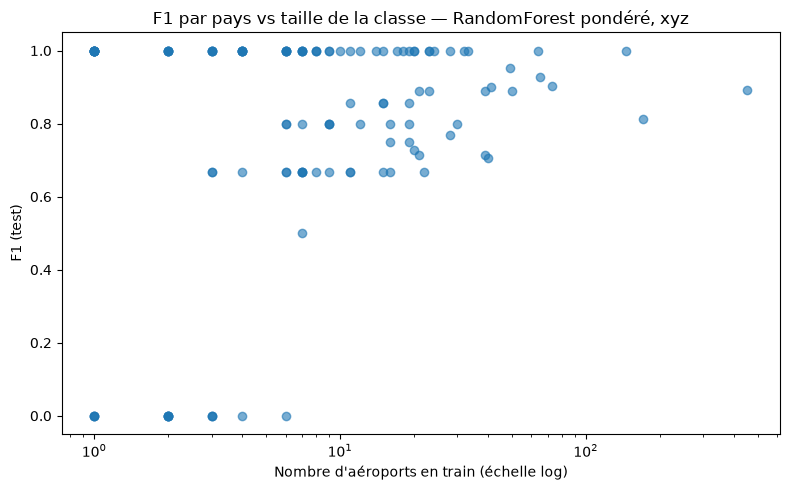

In [60]:
# F1 vs class size: not a clean line (small classes split between "perfectly isolated"
# and "confused with neighbors"), but the trend is visible.

plt.figure(figsize=(8, 5))
plt.scatter(per_class["train_count"], per_class["f1"], alpha=0.6)
plt.xscale("log")
plt.xlabel("Nombre d'aéroports en train (échelle log)")
plt.ylabel("F1 (test)")
plt.title("F1 par pays vs taille de la classe — RandomForest pondéré, xyz")
plt.tight_layout()
plt.show()

Every failure is the true geographic neighbor (Bosnia --> Croatia, etc.), it seems that small countries get absorbed into a larger neighbor's decision boundary.

# Part 2 : Graphe (GNN)

Condition : predict the airport country using the same features than part 1 **plus** the structure of the graph

In [61]:
# Features: xyz (3D unit-sphere coordinates) + log1p(population), not lon/lat.
# Part 1 already showed xyz >= lon/lat for every features-only model, doesn't
# depend on whether a graph is used, so we don't need to re-test lon/lat here.

node_pos = {nid: i for i, nid in enumerate(node_ids)}
edges = np.array([[node_pos[u], node_pos[v]] for u, v in G_filtered.edges()]).T
edge_index = th.tensor(np.concatenate([edges, edges[[1, 0]]], axis=1), dtype=th.long) 
y_t = th.tensor(y, dtype=th.long)
n_nodes = len(y)

print("edge_index:", edge_index.shape, " nodes:", n_nodes)

edge_index: torch.Size([2, 24544])  nodes: 3253


In [62]:
# Generic trainer (weighted CrossEntropyLoss, early stopping on val macro-F1),

def train_gnn(model, X, train_mask, val_mask, class_weights, lr=0.01, weight_decay=5e-4, max_epochs=300, patience=50, seed=0):
    th.manual_seed(seed)
    optimizer = th.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    best_val_f1, best_state, patience_ctr = -1, None, 0
    for epoch in range(max_epochs):
        model.train()
        optimizer.zero_grad()
        out = model(X, edge_index)
        loss = criterion(out[train_mask], y_t[train_mask])
        loss.backward()
        optimizer.step()

        model.eval()
        with th.no_grad():
            pred = model(X, edge_index).argmax(dim=1)
            val_f1 = f1_score(y_t[val_mask].numpy(), pred[val_mask].numpy(), average="macro")

        if val_f1 > best_val_f1:
            best_val_f1, best_state, patience_ctr = val_f1, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                break
    model.load_state_dict(best_state)
    return model, best_val_f1

In [63]:
def evaluate_gnn(model, X, test_mask):
    model.eval()
    with th.no_grad():
        pred = model(X, edge_index).argmax(dim=1)
    return {
        "macro_f1": f1_score(y_t[test_mask].numpy(), pred[test_mask].numpy(), average="macro"),
        "balanced_acc": balanced_accuracy_score(y_t[test_mask].numpy(), pred[test_mask].numpy()),
        "raw_acc": (pred[test_mask] == y_t[test_mask]).float().mean().item(),
    }

In [64]:
class GCN(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.5):
        super().__init__()
        self.conv1 = GCNConv(in_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index).relu()
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)

In [65]:
# GAT

class GAT(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, heads=4, dropout=0.5):
        super().__init__()
        self.conv1 = GATConv(in_dim, hidden_dim, heads=heads, dropout=dropout)
        self.conv2 = GATConv(hidden_dim * heads, out_dim, heads=1, concat=False, dropout=dropout)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.elu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)

In [66]:
# SGC: GCN with the non-linearities removed between layers 

class SGC(nn.Module):
    def __init__(self, in_dim, out_dim, K=2):
        super().__init__()
        self.conv = SGConv(in_dim, out_dim, K=K)

    def forward(self, x, edge_index):
        return self.conv(x, edge_index)

In [67]:
# Run GCN/GAT/SGC over 5 seeds 

def run_gnn_condition(build_X, in_dim, n_seeds=5):
    runs = {"GCN": [], "GAT": [], "SGC": []}
    for seed in range(n_seeds):
        tr, va, te = class_balanced_split(labels, seed=seed)
        train_mask_s = th.zeros(n_nodes, dtype=th.bool); train_mask_s[tr] = True
        val_mask_s = th.zeros(n_nodes, dtype=th.bool); val_mask_s[va] = True
        test_mask_s = th.zeros(n_nodes, dtype=th.bool); test_mask_s[te] = True
        class_weights_s = th.tensor(compute_class_weight("balanced", classes=np.arange(n_classes), y=y[tr]), dtype=th.float)
        X_s = build_X(tr)

        configs = [
            ("GCN", GCN(in_dim, 64, n_classes), 0.01, 5e-4),
            ("GAT", GAT(in_dim, 16, n_classes), 0.005, 5e-4),
            ("SGC", SGC(in_dim, n_classes, K=2), 0.1, 1e-5),
        ]
        for name, model, lr, wd in configs:
            trained, _ = train_gnn(model, X_s, train_mask_s, val_mask_s, class_weights_s, lr=lr, weight_decay=wd, seed=seed)
            runs[name].append(evaluate_gnn(trained, X_s, test_mask_s))
    return runs

In [68]:
# features + structure (xyz), 5 seeds

def build_X_xyz(tr):
    return th.tensor(StandardScaler().fit(X_xyz_raw[tr]).transform(X_xyz_raw), dtype=th.float)


runs_graph_C = run_gnn_condition(build_X_xyz, in_dim=X_xyz_raw.shape[1])
print("(features + structure) done")

(features + structure) done


### Condition B : graph topology only

Same architecture (GCN, GAT, SGC) and same 5 seeds than previously, but each node received the same constant feature ( simple 1)

In [69]:
# topology only, 5 seeds

def build_X_topology(tr):
    return th.ones((n_nodes, 1), dtype=th.float)


runs_graph_B = run_gnn_condition(build_X_topology, in_dim=1)
print("condition B (topology only) done")

condition B (topology only) done


In [70]:
# Final comparison, all three conditions averaged over the same 5 seeds as Part 1:

rows = {"RandomForest (A - features only, xyz)": features_only_table["xyz"].loc["RandomForest (pondéré)"]}
for name, row in summarize_runs(runs_graph_B).iterrows():
    rows[f"{name} (B - topology only)"] = row
for name, row in summarize_runs(runs_graph_C).iterrows():
    rows[f"{name} (C - features + structure)"] = row

final_comparison = pd.DataFrame(rows).T
final_comparison

,macro_f1,balanced_acc,raw_acc
"RandomForest (A - features only, xyz)",0.779 ± 0.018,0.816 ± 0.013,0.868 ± 0.010
GCN (B - topology only),0.003 ± 0.004,0.013 ± 0.009,0.007 ± 0.005
GAT (B - topology only),0.000 ± 0.000,0.008 ± 0.000,0.012 ± 0.006
SGC (B - topology only),0.000 ± 0.000,0.006 ± 0.003,0.002 ± 0.001
GCN (C - features + structure),0.493 ± 0.020,0.552 ± 0.023,0.698 ± 0.011
GAT (C - features + structure),0.252 ± 0.042,0.331 ± 0.038,0.474 ± 0.049
SGC (C - features + structure),0.370 ± 0.031,0.426 ± 0.032,0.579 ± 0.032


Structure alone gives essentially random performance, and adding it to the features never beats RandomForest on features alone,confirming that topology hurts more than it helps on this graph.

### Why doesn't the structure help?

GNNs (GCN/GAT/SGC) implicitly assume that neighbors tend to share the same label.Let's check whether that assumption holds here.

In [71]:
same_country = sum(1 for u, v in G_filtered.edges() if G_filtered.nodes[u]["country"] == G_filtered.nodes[v]["country"])
total_edges = G_filtered.number_of_edges()
print(f"Edge homophily (same-country edges): {same_country}/{total_edges} = {same_country / total_edges:.1%}")

# The hubs (highest-degree nodes) carry the most weight in the aggregation —
# check how many of their neighbors are actually in a different country.
degrees = dict(G_filtered.degree())
top_hubs = sorted(degrees.items(), key=lambda x: -x[1])[:5]
for node, deg in top_hubs:
    own_country = G_filtered.nodes[node]["country"]
    foreign = sum(1 for nb in G_filtered.neighbors(node) if G_filtered.nodes[nb]["country"] != own_country)
    print(f"{G_filtered.nodes[node]['city_name']:15} ({own_country:15}) degree={deg:4d}  foreign_neighbors={foreign:4d} ({foreign/deg:.0%})")

Edge homophily (same-country edges): 7761/12272 = 63.2%
Paris           (FRANCE         ) degree= 225  foreign_neighbors= 179 (80%)
London          (UNITED_KINGDOM ) degree= 214  foreign_neighbors= 198 (93%)
Frankfurt       (GERMANY        ) degree= 206  foreign_neighbors= 188 (91%)
Chicago         (USA            ) degree= 182  foreign_neighbors=  44 (24%)
Amsterdam       (THE_NETHERLANDS) degree= 174  foreign_neighbors= 172 (99%)


We have a Low homophily (63%) and message-passing dilutes exactly the geographic signal that makes the task easy without a graph.